In [1]:
import os
import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, Dataset
import torch.nn.functional as F
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm
import pandas as pd

In [2]:
!pip install kaggle -q

import os
os.makedirs(os.path.expanduser("~/.kaggle"), exist_ok=True)
!cp kaggle.json ~/.kaggle/kaggle.json
!chmod 600 ~/.kaggle/kaggle.json

!kaggle datasets download -d jessicali9530/celeba-dataset --unzip -p ./celeba

cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/jessicali9530/celeba-dataset
License(s): other
100% 1.33G/1.33G [00:11<00:00, 121MB/s]



In [3]:
IMAGE_SIZE = 64
CHANNELS = 3
LABEL_DIM = 2        # Blond_Hair: 0 ou 1
BATCH_SIZE = 128
Z_DIM = 32
LEARNING_RATE = 0.0001
BETA1  = 0.0
BETA2  = 0.9
EPOCHS = 10
CRITIC_STEPS = 5
GP_WEIGHT = 10.0

DEVICE = torch.device("mps" if torch.backends.mps.is_available()
                       else "cuda" if torch.cuda.is_available()
                       else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


In [4]:
ATTR_CSV =  "./celeba/list_attr_celeba.csv"  # ← adapte le chemin si besoin
df = pd.read_csv(ATTR_CSV)

LABEL = "Blond_Hair"

# Convertir de [-1, +1] vers [0, 1]
df[LABEL] = df[LABEL].apply(lambda x: 1 if x == 1 else 0)

img_fnames = df["image_id"].tolist()
labels     = df[LABEL].tolist()

print(img_fnames[:5])
print(labels[:5])
df.head()

['000001.jpg', '000002.jpg', '000003.jpg', '000004.jpg', '000005.jpg']
[0, 0, 0, 0, 0]


,image_id,5_o_Clock_Shadow,Arched_Eyebrows,Attractive,Bags_Under_Eyes,Bald,Bangs,Big_Lips,Big_Nose,Black_Hair,...,Sideburns,Smiling,Straight_Hair,Wavy_Hair,Wearing_Earrings,Wearing_Hat,Wearing_Lipstick,Wearing_Necklace,Wearing_Necktie,Young
0,000001.jpg,-1,1,1,-1,-1,-1,-1,-1,-1,...,-1,1,1,-1,1,-1,1,-1,-1,1
1,000002.jpg,-1,-1,-1,1,-1,-1,-1,1,-1,...,-1,1,-1,-1,-1,-1,-1,-1,-1,1
2,000003.jpg,-1,-1,-1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,1,-1,-1,-1,-1,-1,1
3,000004.jpg,-1,-1,1,-1,-1,-1,-1,-1,-1,...,-1,-1,1,-1,1,-1,1,1,-1,1
4,000005.jpg,-1,1,1,-1,-1,-1,1,-1,-1,...,-1,-1,-1,-1,-1,-1,1,-1,-1,1


In [5]:
class CelebAConditionalDataset(Dataset):
    def __init__(self, root_dir, img_fnames, labels, transform=None):
        self.root_dir   = root_dir
        self.img_fnames = img_fnames
        self.labels     = labels
        self.transform  = transform

    def __len__(self):
        return len(self.img_fnames)

    def __getitem__(self, idx):
        img_path = os.path.join(self.root_dir, self.img_fnames[idx])
        image    = torchvision.io.read_image(img_path)   # (C, H, W), uint8
        label    = self.labels[idx]
        if self.transform:
            image = self.transform(image)
        return image, label


transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ConvertImageDtype(torch.float),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5)),
])

root_dir = "./celeba/img_align_celeba/img_align_celeba"
MAX_SAMPLES = 50000

dataset    = CelebAConditionalDataset(root_dir, img_fnames[:MAX_SAMPLES], labels[:MAX_SAMPLES], transform=transform)
dataloader = DataLoader(dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2, pin_memory=True)
print(f"Dataset size : {len(dataset)}")

Dataset size : 50000


In [6]:
class ConditionalCritic(nn.Module):
    def __init__(self, img_channels=3, label_dim=2, base_features=64):
        super().__init__()
        self.img_channels = img_channels
        self.label_dim    = label_dim

        self.model = nn.Sequential(
            # Input channels = img_channels + label_dim = 3 + 2 = 5
            nn.Conv2d(img_channels + label_dim, base_features,
                      kernel_size=4, stride=2, padding=1),
            nn.LeakyReLU(0.2, inplace=True),

            nn.Conv2d(base_features, base_features * 2,
                      kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(base_features * 2),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            nn.Conv2d(base_features * 2, base_features * 4,
                      kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(base_features * 4),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            nn.Conv2d(base_features * 4, base_features * 8,
                      kernel_size=4, stride=2, padding=1),
            nn.BatchNorm2d(base_features * 8),
            nn.LeakyReLU(0.2, inplace=True),
            nn.Dropout(0.3),

            # Sortie scalaire
            nn.Conv2d(base_features * 8, 1, kernel_size=4, stride=1, padding=0),
            nn.Flatten(start_dim=1)
        )

    def forward(self, image, label):
        # One-hot si nécessaire
        if label.dim() == 1 or label.shape[1] == 1:
            label = F.one_hot(label.long(), num_classes=self.label_dim).float()

        bsz       = label.size(0)
        label_img = label.view(bsz, self.label_dim, 1, 1)\
                         .repeat(1, 1, IMAGE_SIZE, IMAGE_SIZE)  # (B, 2, 64, 64)
        concat    = torch.cat([image, label_img], dim=1)        # (B, 5, 64, 64)
        return self.model(concat)

In [7]:
class ConditionalGenerator(nn.Module):
    def __init__(self, z_dim=32, label_dim=2, img_channels=3, base_features=64):
        super().__init__()
        self.z_dim     = z_dim
        self.label_dim = label_dim

        self.model = nn.Sequential(
            # Input: (z_dim + label_dim, 1, 1) = (34, 1, 1)
            nn.ConvTranspose2d(z_dim + label_dim, base_features * 8,
                               kernel_size=4, stride=1, padding=0, bias=False),
            nn.BatchNorm2d(base_features * 8),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(base_features * 8, base_features * 4,
                               kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(base_features * 4),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(base_features * 4, base_features * 2,
                               kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(base_features * 2),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(base_features * 2, base_features,
                               kernel_size=4, stride=2, padding=1, bias=False),
            nn.BatchNorm2d(base_features),
            nn.LeakyReLU(0.2, inplace=True),

            nn.ConvTranspose2d(base_features, img_channels,
                               kernel_size=4, stride=2, padding=1, bias=False),
            nn.Tanh()   # ← sortie dans [-1, 1]
        )

    def forward(self, noise, label):
        if label.dim() == 1 or label.shape[1] == 1:
            label = F.one_hot(label.long(), num_classes=self.label_dim).float()

        bsz       = label.size(0)
        label_img = label.view(bsz, self.label_dim, 1, 1)
        z_cat     = torch.cat([noise, label_img], dim=1)   # (B, 34, 1, 1)
        return self.model(z_cat)

In [8]:
critic    = ConditionalCritic(img_channels=CHANNELS,
                               label_dim=LABEL_DIM,
                               base_features=64).to(DEVICE)

generator = ConditionalGenerator(z_dim=Z_DIM,
                                  label_dim=LABEL_DIM,
                                  img_channels=CHANNELS,
                                  base_features=64).to(DEVICE)

print("Conditional Critic and Generator successfully initialized!")

Conditional Critic and Generator successfully initialized!


In [9]:
critic_optimizer    = optim.Adam(critic.parameters(),
                                  lr=LEARNING_RATE, betas=(BETA1, BETA2))
generator_optimizer = optim.Adam(generator.parameters(),
                                  lr=LEARNING_RATE, betas=(BETA1, BETA2))


def gradient_penalty(critic, real_imgs, fake_imgs, labels, device=DEVICE):
    bsz, C, H, W = real_imgs.shape
    alpha        = torch.rand(bsz, 1, 1, 1, device=device).expand(bsz, C, H, W)

    # Interpolation entre real et fake
    interpolated = (real_imgs * alpha + fake_imgs.detach() * (1 - alpha))
    interpolated = interpolated.requires_grad_(True)

    critic_score = critic(interpolated, labels)

    grad = torch.autograd.grad(
        inputs=interpolated,
        outputs=critic_score,
        grad_outputs=torch.ones_like(critic_score),
        create_graph=True,
        retain_graph=True
    )[0]

    grad      = grad.view(bsz, -1)
    grad_norm = grad.norm(2, dim=1)
    gp        = torch.mean((grad_norm - 1) ** 2)
    return gp

In [10]:
print("Starting conditional WGAN-GP training!")
g_losses, c_losses = [], []

for epoch in range(EPOCHS):
    progress_bar = tqdm(enumerate(dataloader),
                        total=len(dataloader),
                        desc=f"Epoch {epoch+1}/{EPOCHS}")

    for batch_idx, (real_images, labels) in progress_bar:
        real_images = real_images.to(DEVICE)
        labels      = labels.to(DEVICE)
        cur_bsz     = real_images.size(0)

        # ---- (a) Entraîner le Critic ----
        for _ in range(CRITIC_STEPS):
            noise       = torch.randn(cur_bsz, Z_DIM, 1, 1, device=DEVICE)
            fake_images = generator(noise, labels).detach()  # détaché du graph

            critic_optimizer.zero_grad()
            critic_real   = critic(real_images, labels).view(-1)
            critic_fake   = critic(fake_images, labels).view(-1)
            wass_distance = torch.mean(critic_fake) - torch.mean(critic_real)
            gp            = gradient_penalty(critic, real_images,
                                             fake_images, labels, device=DEVICE)
            critic_loss   = wass_distance + GP_WEIGHT * gp
            critic_loss.backward()
            critic_optimizer.step()

        # ---- (b) Entraîner le Generator ----
        # Nouveau noise + nouveau forward SANS detach
        noise             = torch.randn(cur_bsz, Z_DIM, 1, 1, device=DEVICE)
        fake_images_g     = generator(noise, labels)

        generator_optimizer.zero_grad()
        critic_fake_for_g = critic(fake_images_g, labels).view(-1)
        gen_loss          = -torch.mean(critic_fake_for_g)
        gen_loss.backward()
        generator_optimizer.step()

        c_losses.append(critic_loss.item())
        g_losses.append(gen_loss.item())

        progress_bar.set_postfix({
            "C_Loss"   : f"{critic_loss.item():.4f}",
            "GP"       : f"{gp.item():.4f}",
            "WassDist" : f"{wass_distance.item():.4f}",
            "G_Loss"   : f"{gen_loss.item():.4f}"
        })

Starting conditional WGAN-GP training!


Epoch 10/10: 100%|██████████| 391/391 [07:36<00:00,  1.17s/it, C_Loss=-77.3209, GP=0.7831, WassDist=-85.1521, G_Loss=62.8901]


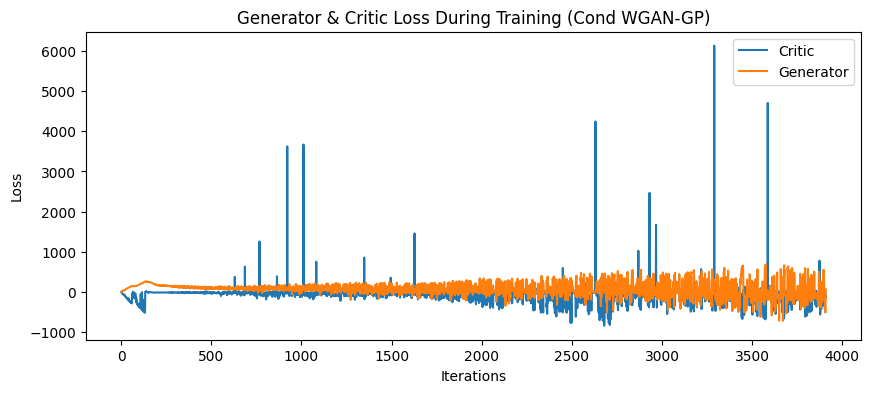

In [11]:
def plot_losses(g_losses, c_losses):
    plt.figure(figsize=(10, 4))
    plt.title("Generator & Critic Loss During Training (Cond WGAN-GP)")
    plt.plot(c_losses, label="Critic")
    plt.plot(g_losses, label="Generator")
    plt.xlabel("Iterations")
    plt.ylabel("Loss")
    plt.legend()
    plt.show()

plot_losses(g_losses, c_losses)

Observations: 

En début d'entraînement, la Critic loss descend fortement en négatif → le critic apprend rapidement à distinguer réel/fake
Les deux losses convergent progressivement vers 0, quand le générateur s'améliore, la distance de Wasserstein diminue
Les pics ponctuels (jusqu'à ~6000) correspondent à des instabilités de la gradient penalty sur certains batchs
Globalement les losses restent bornées et stables → pas de mode collapse complet

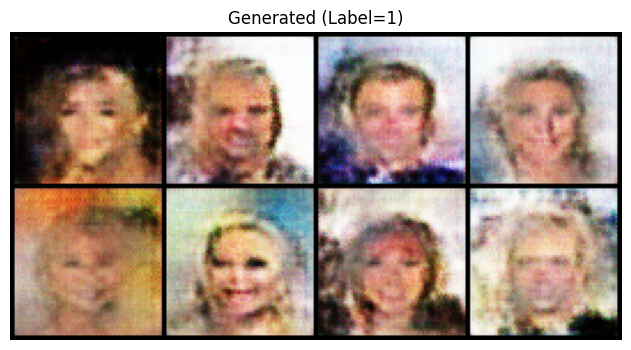

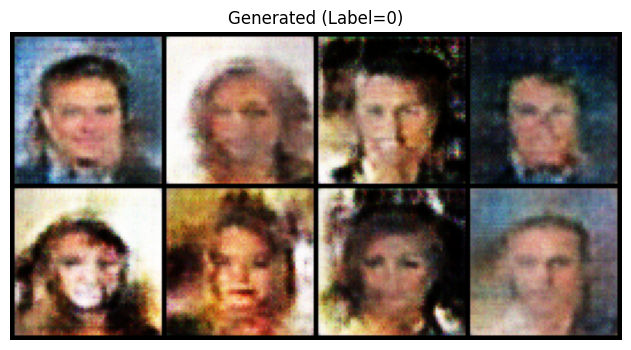

In [12]:
def generate_samples(generator, label, num_samples=8):
    generator.eval()
    noise        = torch.randn(num_samples, Z_DIM, 1, 1).to(DEVICE)
    label_tensor = torch.tensor([label] * num_samples, device=DEVICE)

    with torch.no_grad():
        fake_imgs = generator(noise, label_tensor)

    fake_imgs = fake_imgs.cpu() * 0.5 + 0.5   # dénormalisation [-1,1] → [0,1]
    grid_img  = torchvision.utils.make_grid(fake_imgs, nrow=4)

    plt.figure(figsize=(8, 4))
    plt.imshow(grid_img.permute(1, 2, 0).numpy())
    plt.axis("off")
    plt.title(f"Generated (Label={label})")
    plt.show()
    generator.train()


# Après entraînement :
generate_samples(generator, label=1, num_samples=8)   # Blond Hair
generate_samples(generator, label=0, num_samples=8)   # Non Blond Hair

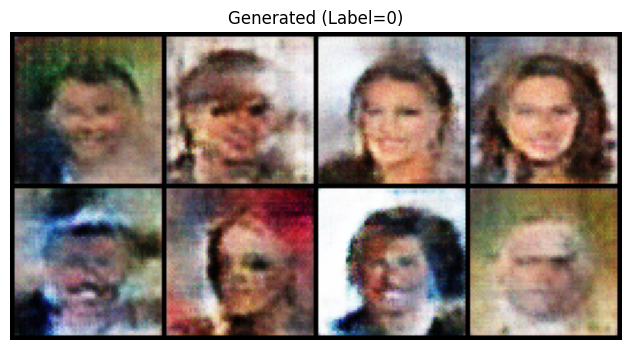

In [14]:
generate_samples(generator, label=0)

In [13]:
torch.save(generator.state_dict(), "generator_cwgan.pth")
torch.save(critic.state_dict(),    "critic_cwgan.pth")